## **Double gyre flow**


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

from ipywidgets import interact, FloatSlider, IntSlider, fixed
import matplotlib.patches as patches

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

from src.datamanager import ROMDataManager
from src.engine import SHREDEngine
from src.train import fit, fit2, evaluate, evaluate2
from src.mSHRED.mSRED import mSHRED

np.random.seed(2025)

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# additional imports for DGF
from helpers import DGFsimulation

## Solver

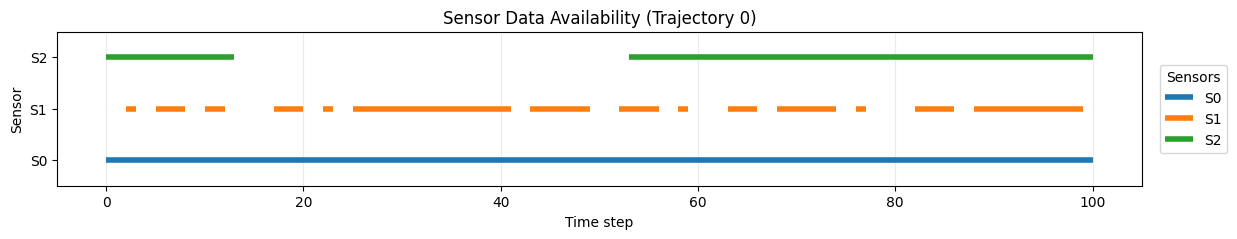

Shape of U:	 (100, 101, 1250) 	Shape of Uraw:	 (100, 101, 50, 25)
Shape of V:	 (100, 101, 1250) 	Shape of Vraw:	 (100, 101, 50, 25)
measurements:	 (100, 101, 3)


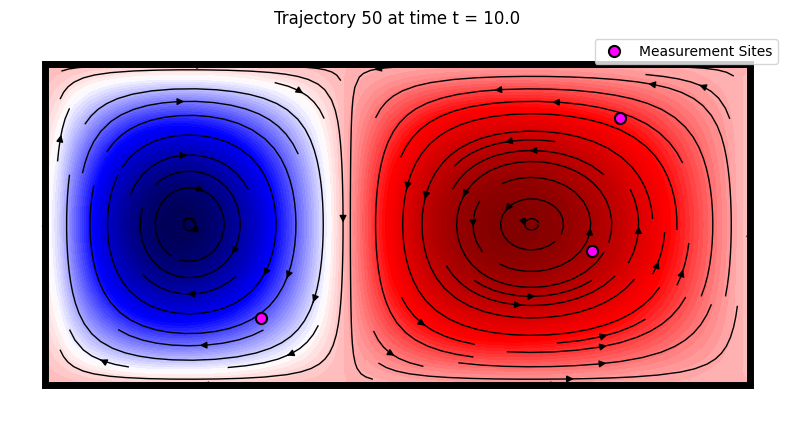

In [3]:
# generate DGF data 
simulator    = DGFsimulation(ntrajectories=100)
Uraw, Vraw   = simulator.generate_data()
U, V         = simulator.get_reshaped_data()
measurements = simulator.generate_measurements_U(
    nsensors=3, idx_short_broken=[1], idx_long_broken=[2], verbose=True, positions=[ 960,  380, 1020]
)

# Debugging 
print("Shape of U:\t", U.shape, "\tShape of Uraw:\t", Uraw.shape)
print("Shape of V:\t", V.shape, "\tShape of Vraw:\t", Vraw.shape)
print("measurements:\t", measurements.shape)
simulator.plot_data(which_trajectory=50)

In [4]:
ERRORS = []

## (T.0) only availabe sensors

In [5]:
# remove the sensors with failed measurements from the data

#vector of always available sensors (i.e. not broken) 
#like we aren't aware of how data are generated
mask = ~np.isnan(measurements).any(axis=(0,1))
measurements_av = measurements[:, :, mask]
print("Available sensors:\t", np.where(mask)[0])

Available sensors:	 [0]


In [6]:
# Data manager
lags = 25
manager = ROMDataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(U, id = "U" , compress = 4, scaler="minmax", measurements = measurements_av)
manager.add_data(V, id = "V" , compress = 4, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 1]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])

Input shape for the model: 1
Output shape for the model: 8


Starting training...


Training:  97%|█████████▋| 145/150 [02:38<00:05,  1.10s/it, Train Loss=0.0024, Val Loss=0.0028, Patience=39, Best Val Loss=0.0026, LR=1.75e-06]

Early stopping at epoch 146
Training completed with best validation loss: 0.0026


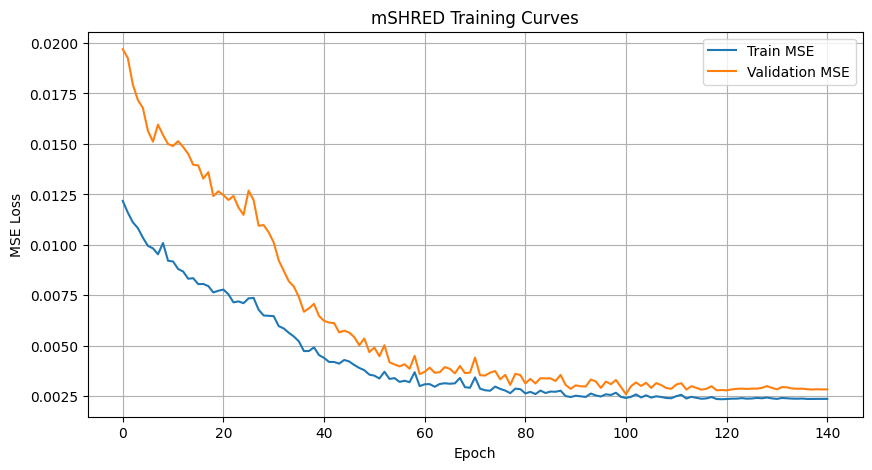

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.00242,0.002606,0.003395,0.057915,0.060146,0.068074


In [7]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=1, input_size=nn_input_shape, n_heads=4,
    dim_feedforward=64, hidden_size=32, input_length=lags, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=150, lr_scheduler="CosineAnnealingLR", scheduler_step_size=150, patience=40, verbose=True,
)

# PLOT TRAINING CURVES
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.0) only available sensors",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse), 
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred


interact(
    simulator.plot_comparison, 
    test_reconstruction=fixed(test_reconstruction), 
    test_idx=fixed(manager.test_indices), 
    which_trajectory=IntSlider(min=0, max=len(manager.test_indices)-1, step=1, value=0), 
    which_time=IntSlider(min=0, max = len(simulator.t)-1, step=1, value=0)
);

## (T.1.A): Median imputer

In [9]:
# Data manager
lags = 25
manager = ROMDataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(U, id = "U" , compress = 4, scaler="minmax", measurements = measurements, imputer="median")
manager.add_data(V, id = "V" , compress = 4, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']
(100, 101, 3)

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


[autoreload of src.utils failed: Traceback (most recent call last):
  File "/home/matteo/miniconda3/envs/mask-shred/lib/python3.10/site-packages/IPython/extensions/autoreload.py", line 276, in check
    superreload(m, reload, self.old_objects)
  File "/home/matteo/miniconda3/envs/mask-shred/lib/python3.10/site-packages/IPython/extensions/autoreload.py", line 475, in superreload
    module = reload(module)
  File "/home/matteo/miniconda3/envs/mask-shred/lib/python3.10/importlib/__init__.py", line 169, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 619, in _exec
  File "<frozen importlib._bootstrap_external>", line 879, in exec_module
  File "<frozen importlib._bootstrap_external>", line 1017, in get_code
  File "<frozen importlib._bootstrap_external>", line 947, in source_to_code
  File "<frozen importlib._bootstrap>", line 241, in _call_with_frames_removed
  File "/home/matteo/Documents/Masked-SHRED/src/utils.py", line 171
    def generate_cha

Starting training...


Training: 100%|██████████| 150/150 [03:08<00:00,  1.26s/it, Train Loss=0.0005, Val Loss=0.0007, Patience=24, Best Val Loss=0.0006, LR=0.00e+00]

Training completed with best validation loss: 0.0006


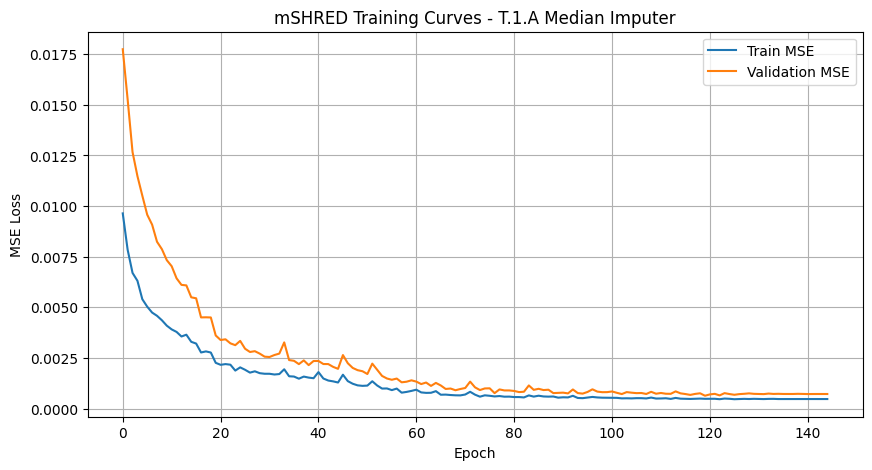

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002420,0.002606,0.003395,0.057915,0.060146,0.068074
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000482,0.000634,0.000466,0.022756,0.025304,0.024838


In [10]:
# mSHRED TRAINING + EVALUATION (T.1.A)
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=1, input_size=nn_input_shape, n_heads=4,
    dim_feedforward=64, hidden_size=32, input_length=lags, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=150, lr_scheduler="CosineAnnealingLR", scheduler_step_size=150, patience=40, verbose=True,
)

# Plot training curves (T.1.A)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.1.A Median Imputer')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.1.A) median imputer",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

[autoreload of src.datamanager failed: Traceback (most recent call last):
  File "/home/matteo/miniconda3/envs/mask-shred/lib/python3.10/site-packages/IPython/extensions/autoreload.py", line 276, in check
    superreload(m, reload, self.old_objects)
  File "/home/matteo/miniconda3/envs/mask-shred/lib/python3.10/site-packages/IPython/extensions/autoreload.py", line 475, in superreload
    module = reload(module)
  File "/home/matteo/miniconda3/envs/mask-shred/lib/python3.10/importlib/__init__.py", line 169, in reload
    _bootstrap._exec(spec, module)
  File "<frozen importlib._bootstrap>", line 619, in _exec
  File "<frozen importlib._bootstrap_external>", line 883, in exec_module
  File "<frozen importlib._bootstrap>", line 241, in _call_with_frames_removed
  File "/home/matteo/Documents/Masked-SHRED/src/datamanager.py", line 11, in <module>
    from .utils import generate_GRUD_4D_input, generate_GRUD_4D_input_3D, generate_channels
ImportError: cannot import name 'generate_GRUD_4D_inp

Mean Relative Error (MRE): 	U: 3.263%	V: 3.590%


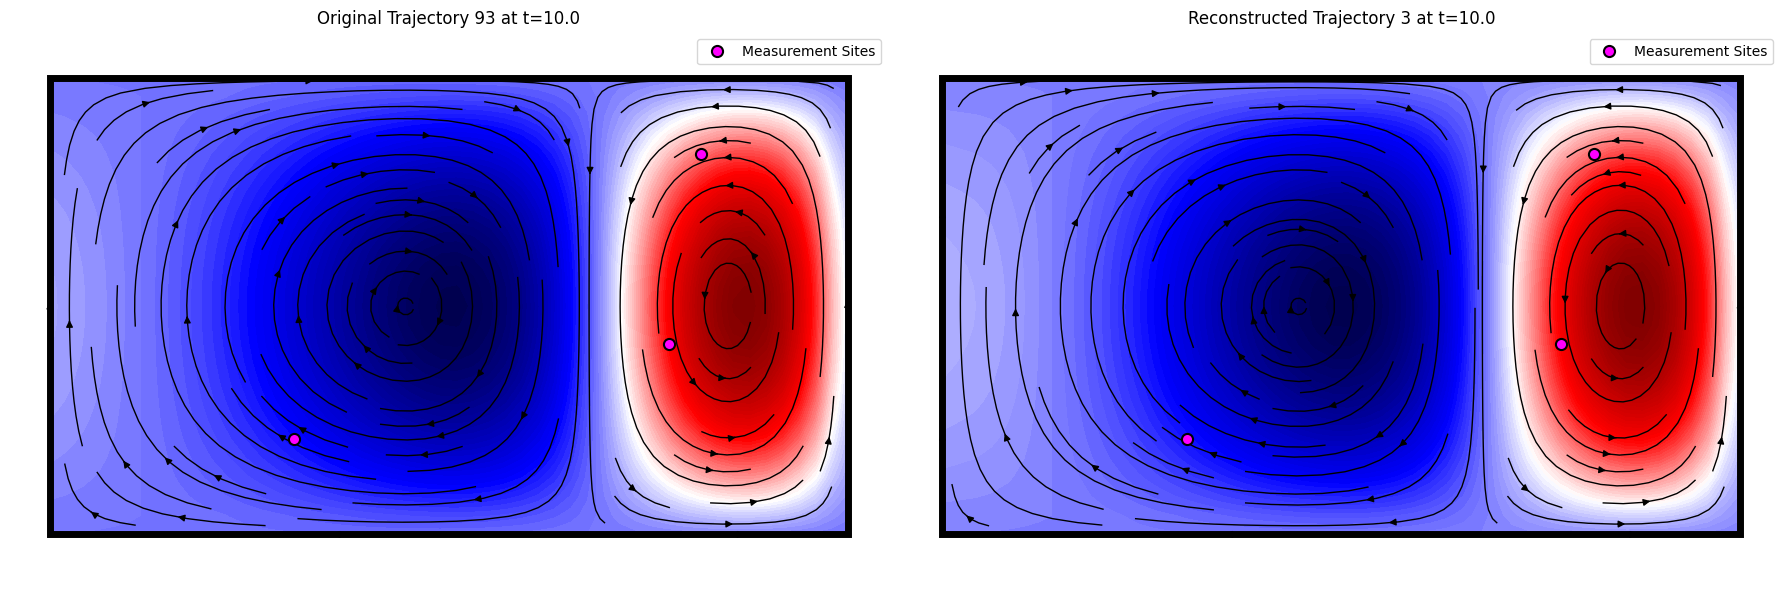

In [11]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## (T.1.B): Mean imputer

In [12]:
# Data manager
lags = 25
manager = ROMDataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(U, id = "U" , compress = 4, scaler="minmax", measurements = measurements, imputer="mean")
manager.add_data(V, id = "V" , compress = 4, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']
(100, 101, 3)

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training: 100%|██████████| 150/150 [04:26<00:00,  1.78s/it, Train Loss=0.0005, Val Loss=0.0009, Patience=30, Best Val Loss=0.0008, LR=0.00e+00]

Training completed with best validation loss: 0.0008


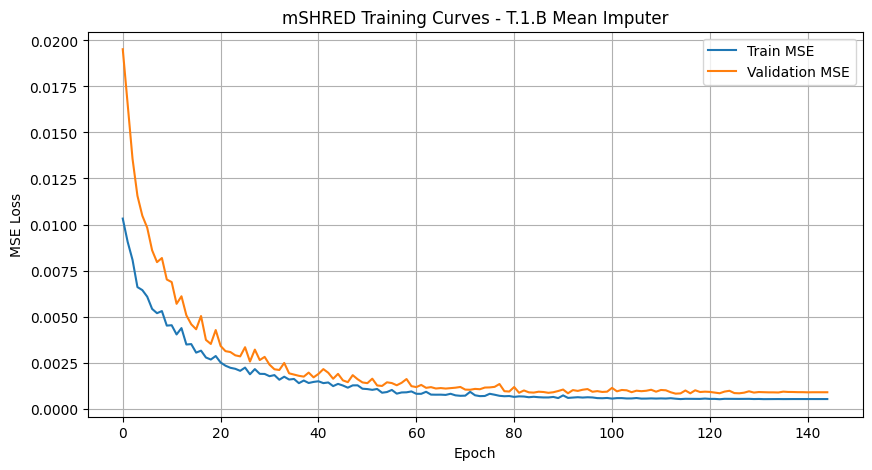

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002420,0.002606,0.003395,0.057915,0.060146,0.068074
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000482,0.000634,0.000466,0.022756,0.025304,0.024838
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000535,0.000810,0.000778,0.022693,0.027303,0.025858


In [13]:
# mSHRED TRAINING + EVALUATION (T.1.B)
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=1, input_size=nn_input_shape, n_heads=4,
    dim_feedforward=64, hidden_size=32, input_length=lags, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=150, lr_scheduler="CosineAnnealingLR", scheduler_step_size=150, patience=40, verbose=True,
)

# Plot training curves (T.1.B)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.1.B Mean Imputer')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.1.B) mean imputer",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 3.134%	V: 3.491%


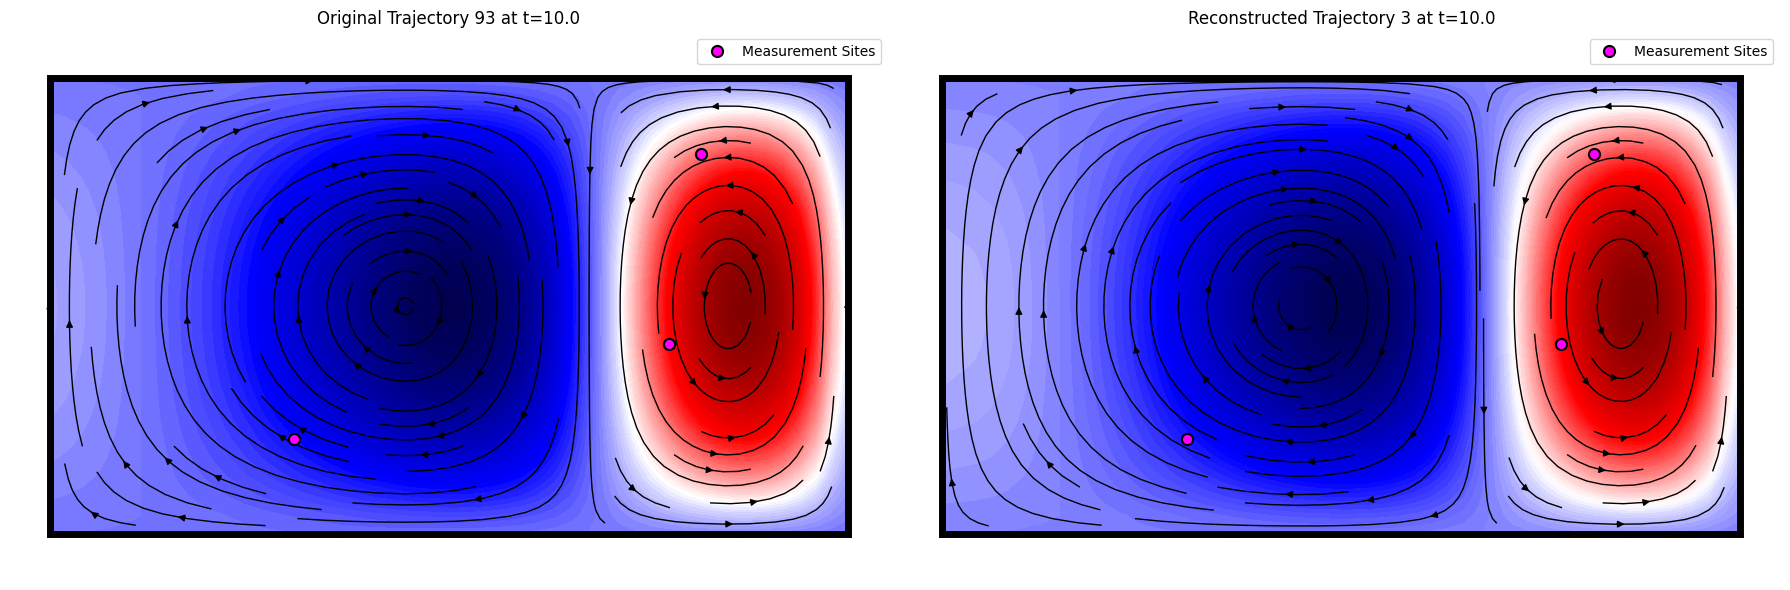

In [14]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## (T.1.C): Last value imputer

In [15]:
# Data manager
lags = 25
manager = ROMDataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(U, id = "U" , compress = 4, scaler="minmax", measurements = measurements, imputer="last_value")
manager.add_data(V, id = "V" , compress = 4, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose = True)

# Debugging: check input and output shapes for the model
nn_input_shape = train_dataset[0][0].shape[1]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 0
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']
(100, 101, 3)

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training: 100%|██████████| 150/150 [03:25<00:00,  1.37s/it, Train Loss=0.0008, Val Loss=0.0011, Patience=28, Best Val Loss=0.0010, LR=0.00e+00]

Training completed with best validation loss: 0.0010


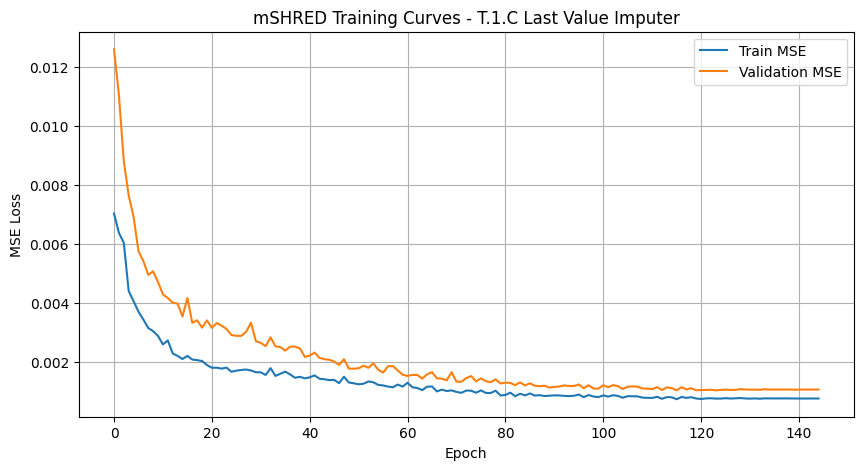

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002420,0.002606,0.003395,0.057915,0.060146,0.068074
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000482,0.000634,0.000466,0.022756,0.025304,0.024838
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000535,0.000810,0.000778,0.022693,0.027303,0.025858
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000742,0.001042,0.001225,0.022727,0.030113,0.028555


In [16]:
# mSHRED TRAINING + EVALUATION (T.1.C)
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=1, input_size=nn_input_shape, n_heads=4,
    dim_feedforward=64, hidden_size=32, input_length=lags, double_channels = False,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=150, lr_scheduler="CosineAnnealingLR", scheduler_step_size=150, patience=40, verbose=True,
)

# Plot training curves (T.1.C)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.1.C Last Value Imputer')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): TR + MLP", "type" : "(T.1.C) last value imputer",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Mean Relative Error (MRE): 	U: 3.857%	V: 4.229%


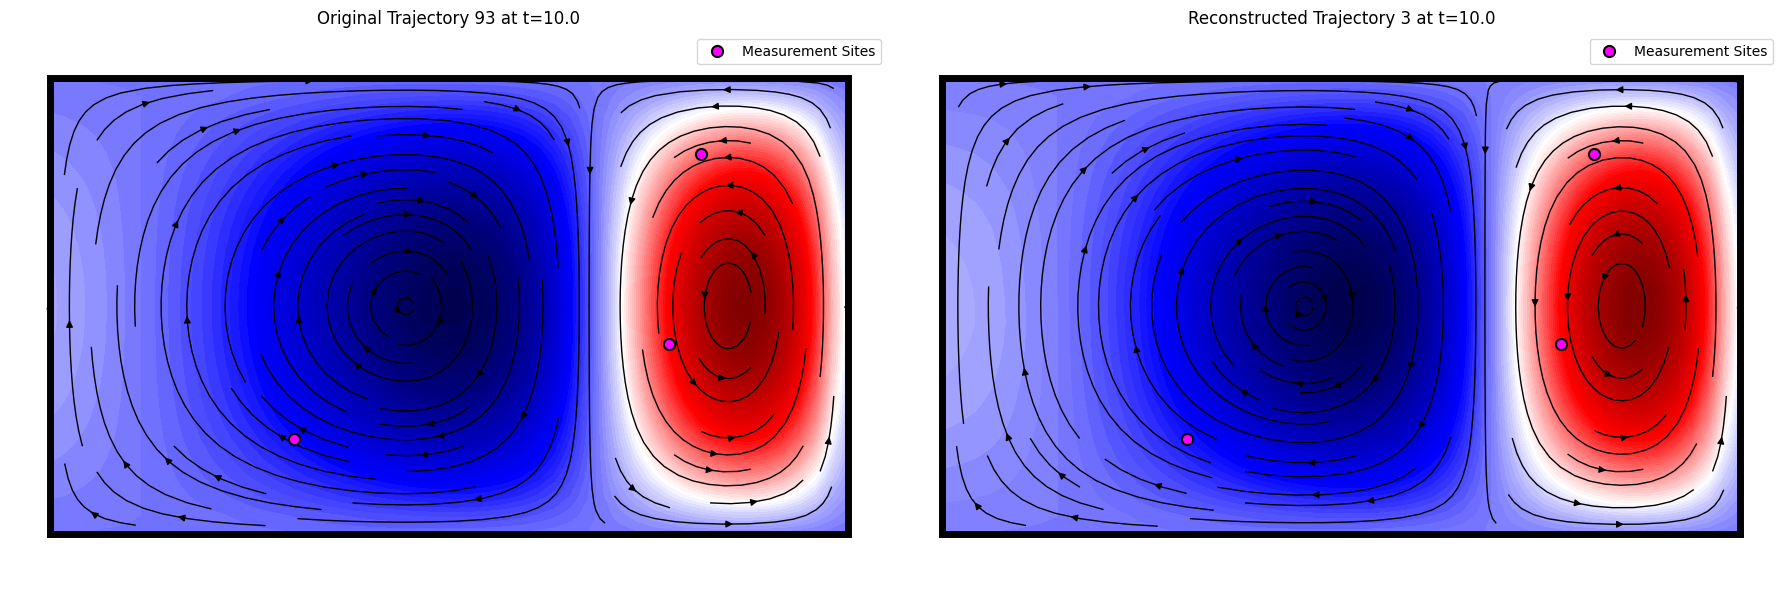

In [17]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## (T.2.A) GRUD

In [28]:
# Data manager
lags = 25
manager = ROMDataManager(lags = lags, train_size = 0.8, val_size = 0.1, test_size = 0.1)

# add data to manager
manager.add_data(U, id = "U" , compress = 4, scaler="minmax", measurements = measurements)
manager.add_data(V, id = "V" , compress = 4, scaler="minmax")
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose = True, masking_type="grud")

# output shape is the compressed (SVD) dimension, not the raw spatial size
nn_input_shape = train_dataset[0][0].shape[2]  # input shape is the number of measurements
nn_output_shape = train_dataset[0][1].shape[0]  # output shape is the compressed (SVD) dimension
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Nuber of nan values in measurements after imputation: 6529
Residual energy of U after keeping 4 modes: 0.0002 %
Residual energy of V after keeping 4 modes: 0.0008 %

Datasets: ['U', 'V']
(10100, 4, 25, 3) (100, 101, 8)

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([8080, 4, 25, 3]) -> torch.Size([8080, 8])
Val:	 torch.Size([1010, 4, 25, 3]) -> torch.Size([1010, 8])
Test:	 torch.Size([1010, 4, 25, 3]) -> torch.Size([1010, 8])

Input shape for the model: 3
Output shape for the model: 8


Starting training...


Training: 100%|██████████| 150/150 [07:27<00:00,  2.98s/it, Train Loss=0.0006, Val Loss=0.0014, Patience=18, Best Val Loss=0.0014, LR=0.00e+00]

Training completed with best validation loss: 0.0014


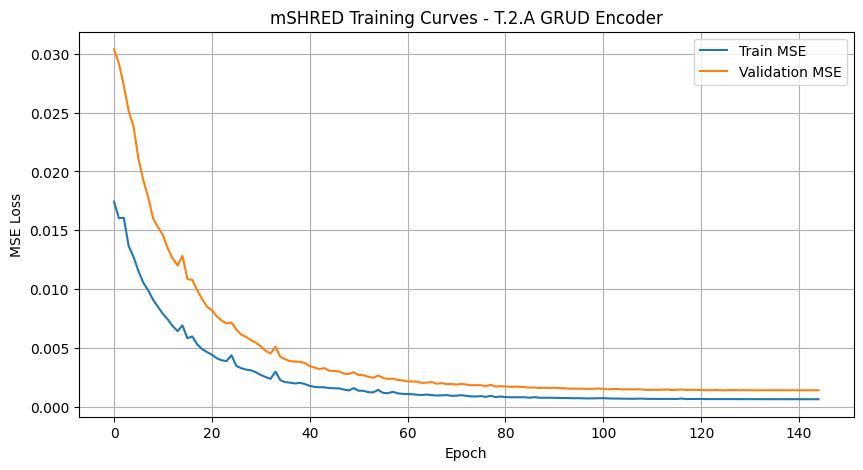

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002420,0.002606,0.003395,0.057915,0.060146,0.068074
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000482,0.000634,0.000466,0.022756,0.025304,0.024838
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000535,0.000810,0.000778,0.022693,0.027303,0.025858
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000742,0.001042,0.001225,0.022727,0.030113,0.028555
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000653,0.001401,0.001312,0.033519,0.045805,0.044010


In [ ]:
# mSHRED TRAINING + EVALUATION (T.2.A) 
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=32, X_mean=X_mean,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=150, lr_scheduler="CosineAnnealingLR", scheduler_step_size=150, patience=40, verbose=True,
)

# Plot training curves (T.2.A)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.2.A GRUD Encoder')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + MLP", "type" : "(T.2.A) GRUD encoder",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}   

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Mean Relative Error (MRE): 	U: 4.395%	V: 4.895%


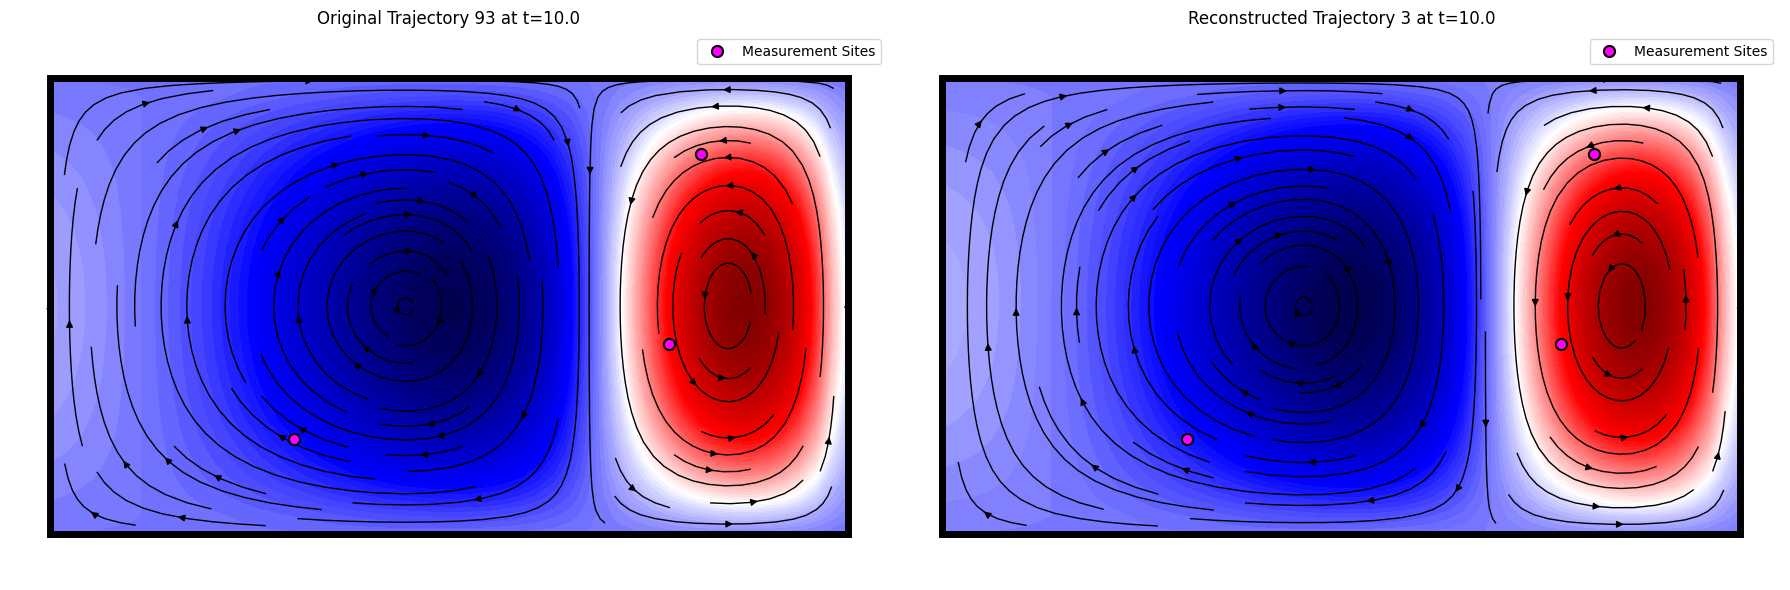

In [30]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

## (T.2.B): Attn-GRUD

Starting training...


Training: 100%|██████████| 150/150 [10:46<00:00,  4.31s/it, Train Loss=0.0007, Val Loss=0.0013, Patience=11, Best Val Loss=0.0013, LR=0.00e+00]

Training completed with best validation loss: 0.0013


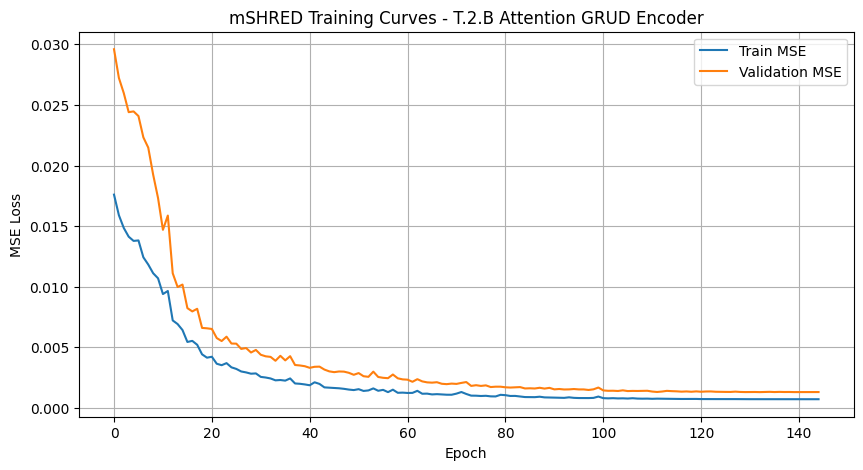

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002420,0.002606,0.003395,0.057915,0.060146,0.068074
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000482,0.000634,0.000466,0.022756,0.025304,0.024838
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000535,0.000810,0.000778,0.022693,0.027303,0.025858
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000742,0.001042,0.001225,0.022727,0.030113,0.028555
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000653,0.001401,0.001312,0.033519,0.045805,0.044010
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000721,0.001305,0.001231,0.034357,0.045211,0.044139


In [31]:
# mSHRED TRAINING + EVALUATION (T.2.B) 
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=32, X_mean=X_mean,
    # Decoder
    decoder="mlp", decoder_hidden_sizes=[], output_size=nn_output_shape, dropout=0.1,
)
mshred = mSHRED(args=model_args).to(device)

train_errors, valid_errors = fit2(
    mshred, train_dataset, val_dataset,
    optimizer="AdamW", lr=1e-3, num_epochs=150, lr_scheduler="CosineAnnealingLR", scheduler_step_size=150, patience=40, verbose=True,
)

# Plot training curves (T.2.B)
plt.figure(figsize=(10, 5))
plt.plot(train_errors[5:], label='Train MSE')
plt.plot(valid_errors[5:], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.title('mSHRED Training Curves - T.2.B Attention GRUD Encoder')
plt.legend(); plt.grid(); plt.show()

# MSE and MRE
train_mse, train_mre = evaluate2(mshred, train_dataset)
val_mse, val_mre = evaluate2(mshred, val_dataset)
test_mse, test_mre = evaluate2(mshred, test_dataset)
test_error = {
    "model": f"(mSHRED): GRUD + MLP", "type" : "(T.2.B) Attention GRUD encoder",
    "train-mse": float(train_mse), "val-mse": float(val_mse), "test-mse": float(test_mse),
    "train-mre": float(train_mre), "val-mre": float(val_mre), "test-mre": float(test_mre),
}   

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)


Mean Relative Error (MRE): 	U: 4.540%	V: 5.109%


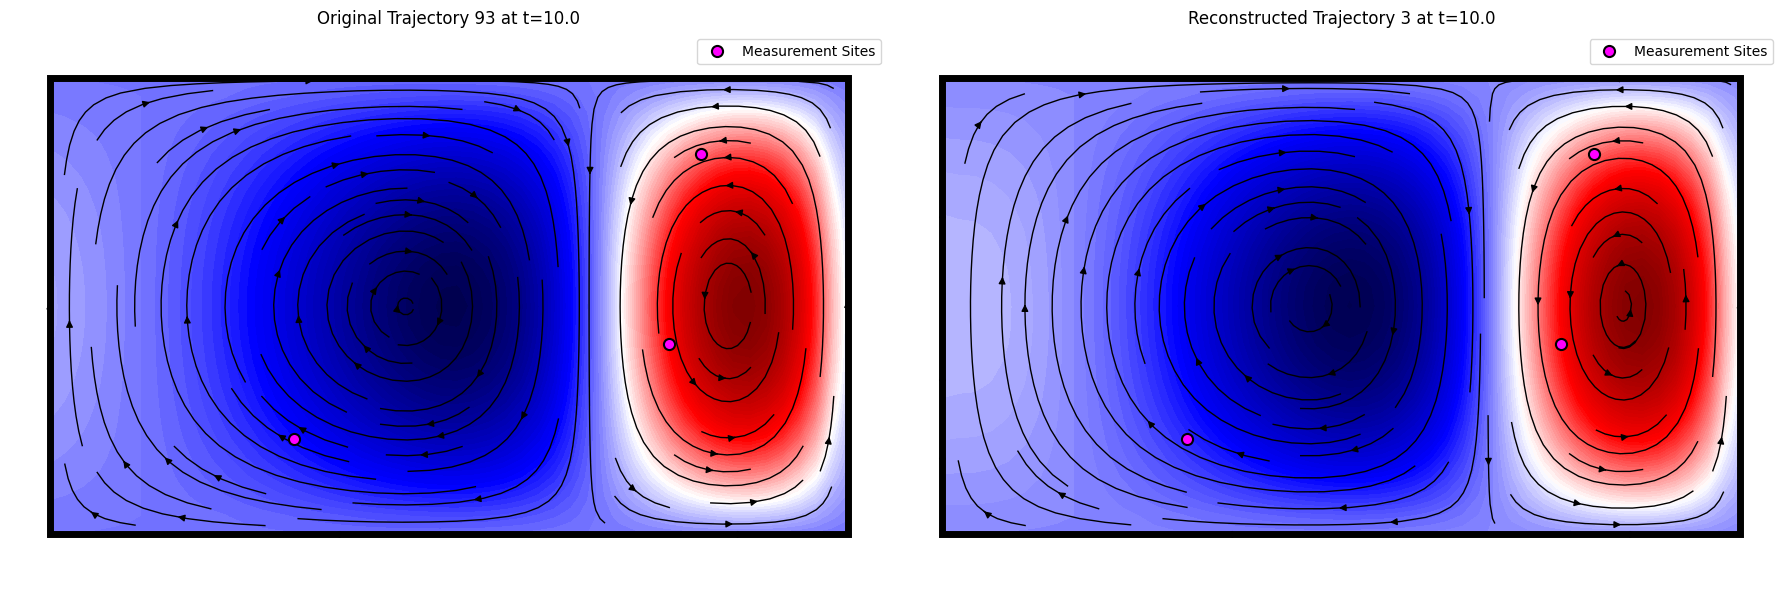

In [32]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
simulator.plot_comparison(test_reconstruction, manager.test_indices , which_trajectory=3)

del train_dataset, val_dataset, test_dataset, manager, test_reconstruction, engine, mshred

## Results

In [33]:
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR + MLP,(T.0) only available sensors,0.002420,0.002606,0.003395,0.057915,0.060146,0.068074
1,(mSHRED): TR + MLP,(T.1.A) median imputer,0.000482,0.000634,0.000466,0.022756,0.025304,0.024838
2,(mSHRED): TR + MLP,(T.1.B) mean imputer,0.000535,0.000810,0.000778,0.022693,0.027303,0.025858
3,(mSHRED): TR + MLP,(T.1.C) last value imputer,0.000742,0.001042,0.001225,0.022727,0.030113,0.028555
4,(mSHRED): GRUD + MLP,(T.2.A) GRUD encoder,0.000653,0.001401,0.001312,0.033519,0.045805,0.044010
5,(mSHRED): GRUD + MLP,(T.2.B) Attention GRUD encoder,0.000721,0.001305,0.001231,0.034357,0.045211,0.044139
